Group 54 Progress Report

Expected Kaggle layout: `/kaggle/input/chest-xray/chest_xray/{train,test}/{NORMAL,PNEUMONIA}`

see comments with `NOTE:` for important parts/key decisions we made

In [26]:

import os, random, json, numpy as np
import torch, torch.nn as nn, torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, SubsetRandomSampler
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix, classification_report)


from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, auc 
)

import matplotlib.pyplot as plt
from PIL import ImageOps

from pathlib import Path


from collections import defaultdict

import torchvision
from pathlib import Path

from torch.cuda.amp import autocast, GradScaler


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

IMG_SIZE = 160
BATCH_SIZE = 64
EPOCHS_PHASE_A = 1000
EPOCHS_PHASE_B = 3
PATIENCE = 3
VAL_SPLIT = 0.10

## NOTE: reduce data/use a subset of the dataset:
# REDUCE_DATA = True
# REDUCTION_FACTOR = 1 # 10
# MAX_TRAIN_BATCHES = 100
# MAX_VAL_BATCHES   = 50
REDUCE_DATA = False     # <- no downsampling
REDUCTION_FACTOR = 1
MAX_TRAIN_BATCHES = None
MAX_VAL_BATCHES   = None


LR_HEAD = 2e-3
LR_FINETUNE = 1e-4
USE_HIST_EQUALIZE = True
POSITIVE_CLASS_NAME = "PNEUMONIA"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "/kaggle/working/report_artifacts"
os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", DEVICE)

# Define standard normalization parameters
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]


Device: cuda


In [15]:



#NOTE: update the path here, if not using kaggle

candidates = [
    Path("/kaggle/input/chest-xray/chest_xray"),
    Path("/kaggle/input/chest_xray/chest_xray"),
    Path("/kaggle/input/chest-xray"),
    Path("/kaggle/input/chest_xray"),
]
DATA_ROOT=None
for p in candidates:
    if (p/"train").exists() and (p/"test").exists():
        DATA_ROOT=p; break

TRAIN_DIR = DATA_ROOT/"train"; TEST_DIR = DATA_ROOT/"test"
print("DATA_ROOT:", DATA_ROOT)
print("train exists:", TRAIN_DIR.exists(), "test exists:", TEST_DIR.exists())


DATA_ROOT: /kaggle/input/chest-xray/chest_xray
train exists: True test exists: True


In [19]:
class OptionalEqualize:
    def __init__(self, enabled: bool): self.enabled = enabled
    def __call__(self, img):
        if not self.enabled: return img
        
        gray = img.convert("L"); eq = ImageOps.equalize(gray); return eq.convert("RGB")

# NEW: Define normalization parameters for clarity
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

# Training Transforms (tf_train) - CORRECTED
tf_train = transforms.Compose([
    # Enhancement/Color (Conditional, Deterministic)
    OptionalEqualize(USE_HIST_EQUALIZE),
    transforms.Grayscale(num_output_channels=3),
    
    # Resizing/Cropping (Standardization + Augmentation)
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.9, 1.05), ratio=(0.95, 1.05)),
    
    # Rotations 
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), shear=5),
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ToTensor(),
    
    # 6. tensor augmentation & preprocessing
    transforms.ColorJitter(brightness=0.05, contrast=0.05), 
    transforms.RandomErasing(p=0.1, scale=(0.01, 0.05), value='random'),
    
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

# Evaluation Transforms (tf_eval) 
tf_eval = transforms.Compose([
    OptionalEqualize(USE_HIST_EQUALIZE),
    transforms.Grayscale(num_output_channels=3), 
    transforms.Resize((IMG_SIZE, IMG_SIZE)), 
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])
print("Transforms ready.")

Transforms ready.


Class identifirs: {'NORMAL': 0, 'PNEUMONIA': 1}
full dataset: True (factor of reduction:1)
Sizes, Train:4708 Val:524 Test:624
Class weights: [3.87808895111084, 1.3474527597427368]


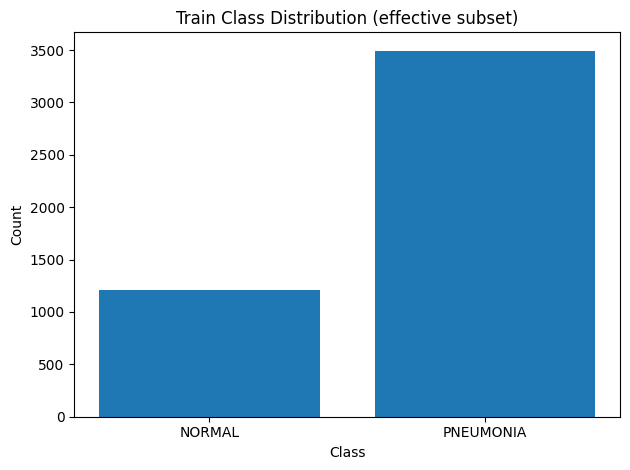

In [20]:

train_full_ds = datasets.ImageFolder(root=str(TRAIN_DIR), transform=tf_train)
val_view_ds   = datasets.ImageFolder(root=str(TRAIN_DIR), transform=tf_eval)
test_ds       = datasets.ImageFolder(root=str(TEST_DIR),  transform=tf_eval)

class_to_idx = train_full_ds.class_to_idx
idx_to_class = {v:k for k,v in class_to_idx.items()}
print("Class identifirs:", class_to_idx)

train_labels = np.array([y for _, y in train_full_ds.samples])

sss = StratifiedShuffleSplit(n_splits=1, test_size=VAL_SPLIT, random_state=SEED)
all_idx = np.arange(len(train_labels))
train_idx_full, val_idx_full = next(sss.split(np.zeros(len(train_labels)), train_labels))


random.seed(SEED)

#NOTE: where the data subset is taken
def stratified_downsample_indices(dataset, indices, factor):
    if not REDUCE_DATA or factor <= 1: return np.array(indices)
    by_class = defaultdict(list)
    for i in indices:
        _, y = dataset.samples[i]
        by_class[y].append(i)
    keep=[]
    for y, idxs in by_class.items():
        k = max(1, len(idxs)//factor)
        keep.extend(random.sample(idxs, k))
    return np.array(keep)

train_idx = stratified_downsample_indices(train_full_ds, train_idx_full, REDUCTION_FACTOR)
val_idx   = stratified_downsample_indices(train_full_ds, val_idx_full,   REDUCTION_FACTOR)
test_all  = np.arange(len(test_ds.samples))
test_idx  = stratified_downsample_indices(test_ds,       test_all,       REDUCTION_FACTOR)

train_sampler = SubsetRandomSampler(train_idx)
val_sampler   = SubsetRandomSampler(val_idx)
test_sampler  = SubsetRandomSampler(test_idx)

train_loader = DataLoader(train_full_ds, batch_size=BATCH_SIZE, sampler=train_sampler,
                          num_workers=4, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val_view_ds,   batch_size=BATCH_SIZE, sampler=val_sampler,
                          num_workers=4, pin_memory=True, persistent_workers=True)
test_loader  = DataLoader(test_ds,       batch_size=BATCH_SIZE, sampler=test_sampler,
                          num_workers=4, pin_memory=True, persistent_workers=True)

train_labels_used = np.array([train_full_ds.samples[i][1] for i in train_idx])
classes, counts = np.unique(train_labels_used, return_counts=True)
class_counts = {int(c): int(n) for c,n in zip(classes, counts)}
class_weights = torch.tensor([len(train_labels_used)/class_counts.get(c,1) for c in range(len(class_to_idx))],
                             dtype=torch.float32, device=torch.device("cuda" if torch.cuda.is_available() else "cpu"))

print(f"full dataset: {(not REDUCE_DATA)} (factor of reduction:{REDUCTION_FACTOR})")
print(f"Sizes, Train:{len(train_idx)} Val:{len(val_idx)} Test:{len(test_idx)}")
print("Class weights:", class_weights.tolist())


plt.figure(); plt.bar([idx_to_class[i] for i in class_counts.keys()], [class_counts[i] for i in class_counts.keys()])
plt.title("Train Class Distribution (effective subset)"); plt.xlabel("Class"); plt.ylabel("Count")
plt.tight_layout(); plt.show()


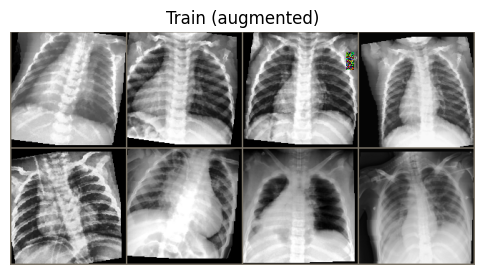

In [21]:


# NOTE: See augmentations (to the training set, to reduce overfitting)
def denorm(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (img * std + mean).clamp(0, 1)

# Grab a batch
xb, yb = next(iter(train_loader))
grid = torchvision.utils.make_grid(xb[:8], nrow=4)

plt.figure(figsize=(6,6))
plt.imshow(denorm(grid).permute(1, 2, 0))
plt.axis("off")
plt.title("Train (augmented)")
plt.show()


In [22]:

torch.backends.cudnn.benchmark = True

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in model.parameters(): p.requires_grad = False
in_feats = model.fc.in_features
model.fc = nn.Linear(in_feats, len(class_to_idx))
model = model.to(torch.device("cuda" if torch.cuda.is_available() else "cpu"))

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05) # add label smoothing regularization
optimizer = optim.Adam(model.fc.parameters(), lr=LR_HEAD, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)


scaler = GradScaler(enabled=torch.cuda.is_available())

def run_epoch(loader, train=False, max_batches=None):
    model.train(train)
    seen = 0
    total_loss=0.0; y_true=[]; y_pred=[]; y_prob=[]
    for b, (xb,yb) in enumerate(loader):
        xb = xb.to(torch.device("cuda" if torch.cuda.is_available() else "cpu"), non_blocking=True)
        yb = yb.to(torch.device("cuda" if torch.cuda.is_available() else "cpu"), non_blocking=True)
        if train: optimizer.zero_grad(set_to_none=True)
        with autocast(enabled=torch.cuda.is_available()):
            logits = model(xb)
            loss = criterion(logits, yb)
        if train:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        seen += yb.size(0)
        total_loss += loss.item()*yb.size(0)
        probs = torch.softmax(logits, dim=1) # probabilities
        preds = probs.argmax(1)
        y_true += yb.detach().cpu().tolist()
        y_pred += preds.detach().cpu().tolist()
        y_prob += probs.detach().cpu().tolist()
        if max_batches and (b+1)>=max_batches: break
    # avg_loss = total_loss / max(1, len(loader.sampler))
    avg_loss = total_loss / max(seen, 1)
    return avg_loss, np.array(y_true), np.array(y_pred), np.array(y_prob)

def compute_metrics(y_true, y_pred, y_prob, pos_index):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary',
                                                       pos_label=pos_index, zero_division=0)
    try:
        auc = roc_auc_score((y_true==pos_index).astype(int), y_prob[:, pos_index])
    except Exception:
        auc = float('nan')
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "roc_auc": auc, "cm": cm}

def plot_confusion(cm, title):

    plt.figure(); plt.imshow(cm, interpolation='nearest'); plt.title(title); plt.colorbar()
    tick = np.arange(len(class_to_idx))
    plt.xticks(tick, [list(idx_to_class.values())[i] for i in range(len(class_to_idx))], rotation=45)
    plt.yticks(tick, [list(idx_to_class.values())[i] for i in range(len(class_to_idx))])
    thresh = cm.max()/2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, format(cm[i,j],'d'), ha="center", va="center",
                     color="white" if cm[i,j]>thresh else "black")
    plt.ylabel("True"); plt.xlabel("Pred"); plt.tight_layout(); plt.show()

print("Model ready. Trainable params:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Model ready. Trainable params: 1026


/tmp/ipykernel_47/302347376.py:14: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=torch.cuda.is_available())



 Starting Phase A: Head Training (Feature Extraction)


/tmp/ipykernel_47/302347376.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


[A][1/1000] train_loss=0.4207 val_loss=0.3932 val_acc=0.849 val_f1=0.890


/tmp/ipykernel_47/302347376.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


[A][2/1000] train_loss=0.3727 val_loss=0.5091 val_acc=0.710 val_f1=0.758


/tmp/ipykernel_47/302347376.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


[A][3/1000] train_loss=0.3619 val_loss=0.4114 val_acc=0.786 val_f1=0.833


/tmp/ipykernel_47/302347376.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


[A][4/1000] train_loss=0.3381 val_loss=0.5189 val_acc=0.687 val_f1=0.734
Early stopping.


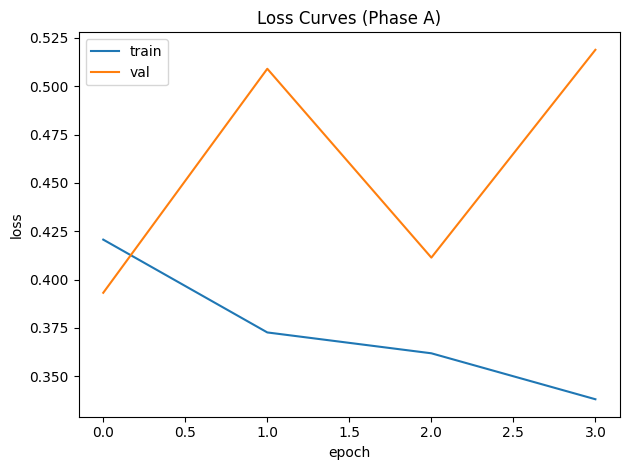

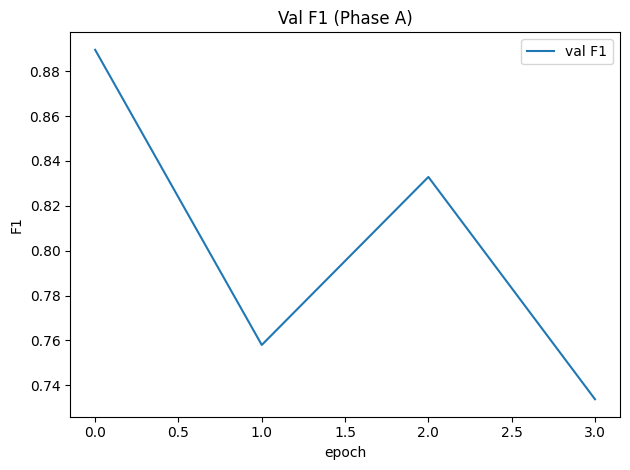

Best val F1 from Phase A: 0.8895104895104895


In [23]:
pos_idx = class_to_idx[POSITIVE_CLASS_NAME]
history_a={ # Phase A results
    "train_loss":[],
    "val_loss":[],
    "val_f1":[]
}
best_f1=-1
no_improvement=0
print("\n Starting Phase A: Head Training (Feature Extraction)") 
for epoch in range(EPOCHS_PHASE_A):
    tr_loss, tr_y, tr_p, tr_prob = run_epoch(train_loader, train=True,  max_batches=MAX_TRAIN_BATCHES)
    va_loss, va_y, va_p, va_prob = run_epoch(val_loader,   train=False, max_batches=MAX_VAL_BATCHES)
    scheduler.step(va_loss)
    metrics = compute_metrics(va_y, va_p, va_prob, pos_idx)
    history_a["train_loss"].append(tr_loss)
    history_a["val_loss"].append(va_loss)
    history_a["val_f1"].append(metrics["f1"])
    print(f"[A][{epoch+1}/{EPOCHS_PHASE_A}] train_loss={tr_loss:.4f} val_loss={va_loss:.4f} val_acc={metrics['accuracy']:.3f} val_f1={metrics['f1']:.3f}")
    if metrics["f1"] > best_f1 + 1e-4:
        best_f1=metrics["f1"]
        no_improvement=0
        torch.save(model.state_dict(), os.path.join(OUT_DIR, "best_resnet18_head.pth"))
    else:
        no_improvement += 1
        if no_improvement >= PATIENCE:
            print("Early stopping.")
            break

plt.figure()
plt.plot(history_a["train_loss"], label="train")
plt.plot(history_a["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Loss Curves (Phase A)") 
plt.legend()
plt.tight_layout()
plt.show()
plt.figure()
plt.plot(history_a["val_f1"], label="val F1") 
plt.xlabel("epoch")
plt.ylabel("F1")
plt.title("Val F1 (Phase A)")
plt.legend()
plt.tight_layout()
plt.show()
print("Best val F1 from Phase A:", best_f1)


--- Starting Phase B: Shallow Fine-Tuning ---
Total trainable parameters for Phase B: 8,394,754
Fine-Tuning for max 3 epochs with LR=0.0001


/tmp/ipykernel_47/302347376.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


[B][1/3] train_loss=0.3123 val_loss=0.3473 val_acc=0.863 val_f1=0.899


/tmp/ipykernel_47/302347376.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


[B][2/3] train_loss=0.2604 val_loss=0.2996 val_acc=0.906 val_f1=0.934


/tmp/ipykernel_47/302347376.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


[B][3/3] train_loss=0.2421 val_loss=0.2728 val_acc=0.931 val_f1=0.952


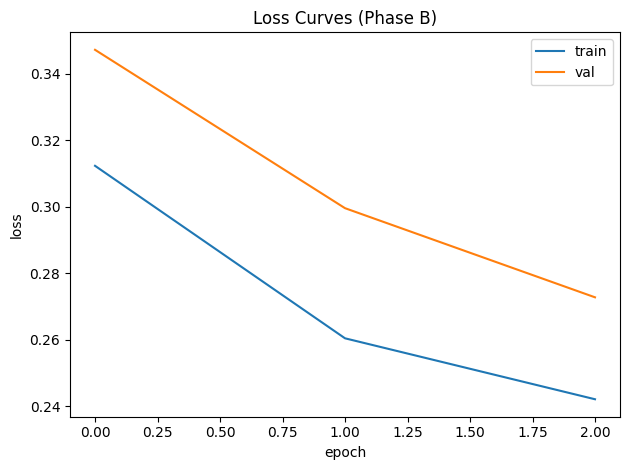

Best val F1 after Phase B: 0.9521276595744681


In [24]:
# PHASE B: SHALLOW FINE-TUNING
# Purpose: Adapt the high-level features of the last block to X-ray specific patterns.

# Load the best weights from Phase A before starting Phase B
best_head_a = os.path.join(OUT_DIR, "best_resnet18_head_phase_a.pth")
if os.path.exists(best_head_a):
    device_load = "cuda" if torch.cuda.is_available() else "cpu"
    model.load_state_dict(torch.load(best_head_a, map_location=device_load))

print("\n--- Starting Phase B: Shallow Fine-Tuning ---")

# 1. Enable gradient updates for all parameters
for param in model.parameters():
    param.requires_grad = True

# 2. Keep only the last convolutional block ('layer4') and the head ('fc') trainable
for name, param in model.named_parameters():
    if not ('layer4' in name or 'fc' in name):
        param.requires_grad = False

# 3. Verify the number of unfrozen layers
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters for Phase B: {trainable_params:,}")

# 4. Optimizer for fine-tuning (uses the smaller LR_FINETUNE)
optimizer_finetune = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR_FINETUNE,
    weight_decay=1e-4
)

# Scheduler reset for the fine-tuning phase
scheduler_b = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_finetune, mode='min', factor=0.5, patience=1
)

# Tracking for Phase B
history_b = {
    "train_loss": [], "val_loss": [], "val_f1": []
}

best_f1_b = best_f1      # Start from Phase A’s best F1
no_improvement_b = 0

# 5. Training loop for Phase B
print(f"Fine-tuning for up to {EPOCHS_PHASE_B} epochs with LR={LR_FINETUNE}")
for epoch in range(EPOCHS_PHASE_B):

    # Temporary reassignment so run_epoch uses the fine-tuning optimizer
    optimizer = optimizer_finetune

    tr_loss, tr_y, tr_p, tr_prob = run_epoch(
        train_loader, train=True, max_batches=MAX_TRAIN_BATCHES
    )
    va_loss, va_y, va_p, va_prob = run_epoch(
        val_loader, train=False, max_batches=MAX_VAL_BATCHES
    )
    scheduler_b.step(va_loss)
    metrics = compute_metrics(va_y, va_p, va_prob, pos_idx)
    history_b["train_loss"].append(tr_loss)
    history_b["val_loss"].append(va_loss)
    history_b["val_f1"].append(metrics["f1"])
    print(f"[B][{epoch+1}/{EPOCHS_PHASE_B}] train_loss={tr_loss:.4f} val_loss={va_loss:.4f} val_acc={metrics['accuracy']:.3f} val_f1={metrics['f1']:.3f}") # NEW: Added [B] prefix
    
    if metrics["f1"] > best_f1_b + 1e-4:
        best_f1_b=metrics["f1"]
        no_improvement_b=0
        # saving the best weights from Phase B
        torch.save(model.state_dict(), os.path.join(OUT_DIR, "best_resnet18_head.pth")) # Overwrites the original best_resnet18_head.pth
    else:
        no_improvement_b += 1
        if no_improvement_b >= PATIENCE:
            print("Early stopping Phase B.")
            break
            
# Phase B results
plt.figure()
plt.plot(history_b["train_loss"], label="train") 
plt.plot(history_b["val_loss"], label="val")   
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Loss Curves (Phase B)") 
plt.legend()
plt.tight_layout()
plt.show()
print("Best val F1 after Phase B:", best_f1_b)

/tmp/ipykernel_47/302347376.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


TEST CNN
{
  "accuracy": 0.9391025641025641,
  "precision": 0.9607329842931938,
  "recall": 0.941025641025641,
  "f1": 0.9507772020725389,
  "roc_auc": 0.9859467455621301
}
Confusion matrix:
[[219  15]
 [ 23 367]]


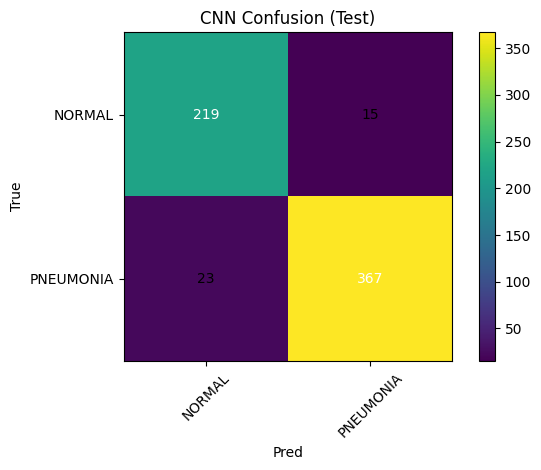

Metrics with Optimized Threshold: 0.20
{
  "accuracy": 0.9214743589743589,
  "precision": 0.9011764705882352,
  "recall": 0.982051282051282,
  "f1": 0.939877300613497,
  "roc_auc": 0.9859467455621301
}
Confusion matrix (Optimized Recall):
[[192  42]
 [  7 383]]


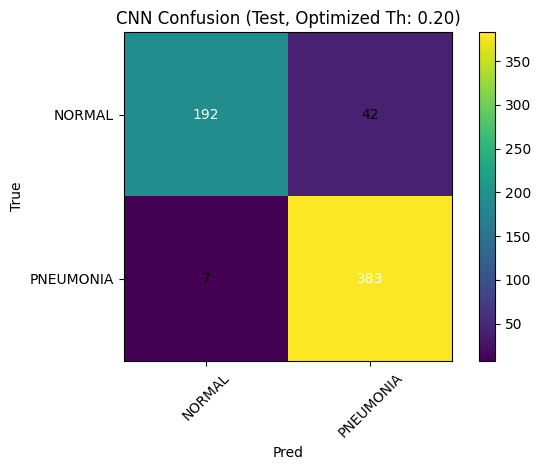

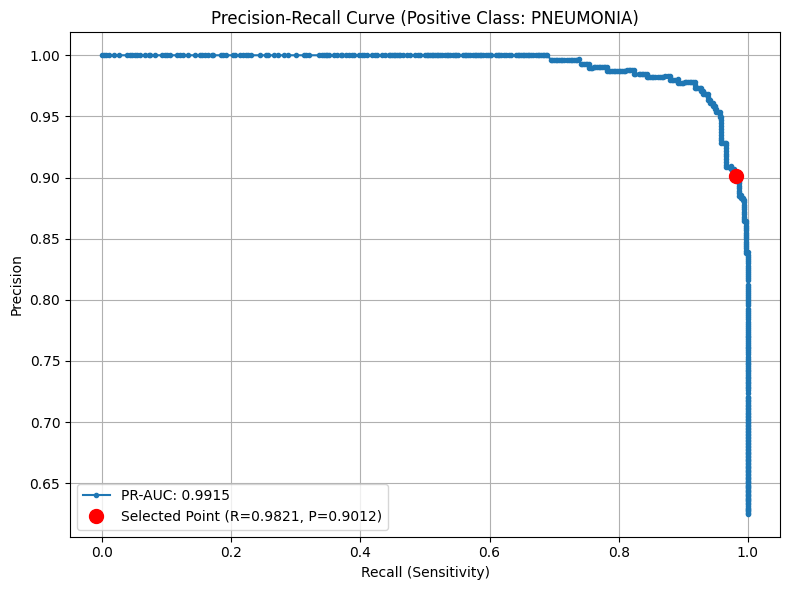

TEST Majority Baseline
{
  "accuracy": 0.625,
  "precision": 0.625,
  "recall": 1.0,
  "f1": 0.7692307692307693,
  "roc_auc": 0.5
}
Artifacts saved in: /kaggle/working/report_artifacts


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [27]:

# use best head weights
best_head = os.path.join(OUT_DIR, "best_resnet18_head.pth")
if os.path.exists(best_head):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.load_state_dict(torch.load(best_head, map_location=device))
# majority baseline from effective train subset
majority_label = int(max(class_counts, key=class_counts.get))

# CNN on test set
te_loss, te_y, te_p, te_prob = run_epoch(test_loader, train=False, max_batches=None)
test_metrics = compute_metrics(te_y, te_p, te_prob, pos_idx)
print("TEST CNN")
print(json.dumps(
    {k: float(v) if not isinstance(v, np.ndarray) else "array"
     for k, v in test_metrics.items() if k != "cm"},
    indent=2
))
print("Confusion matrix:")
print(test_metrics["cm"])
plot_confusion(test_metrics["cm"], "CNN Confusion (Test)")

#updated 
CUSTOM_THRESHOLD = 0.20
POSITIVE_CLASS_INDEX = pos_idx

# Extract Scores and Labels
y_scores = te_prob[:, POSITIVE_CLASS_INDEX]  # Probability scores for the positive class (PNEUMONIA)

# Metrics with the New Threshold
y_pred_optimized = (y_scores >= CUSTOM_THRESHOLD).astype(int)
# Calculate the metrics for the optimized 0.25 threshold
optimized_metrics = compute_metrics(y_true=te_y, y_pred=y_pred_optimized, y_prob=te_prob, pos_index=pos_idx)

print(f"Metrics with Optimized Threshold: {CUSTOM_THRESHOLD:.2f}")
print(json.dumps({k: float(v) if not isinstance(v, np.ndarray) else 'array'
                  for k, v in optimized_metrics.items() if k != "cm"}, indent=2))
print("Confusion matrix (Optimized Recall):")
print(optimized_metrics['cm'])
plot_confusion(optimized_metrics['cm'], title=f"CNN Confusion (Test, Optimized Th: {CUSTOM_THRESHOLD:.2f})")

# Calculate PR curve for plotting
precision, recall, thresholds = precision_recall_curve(te_y, y_scores)
auc_pr = auc(recall, precision)

# Plot Precision-Recall Curve 
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label=f'PR-AUC: {auc_pr:.4f}')
# Optimal point on the curve
plt.plot(optimized_metrics['recall'], optimized_metrics['precision'], 'o', 
         markersize=10, color='red', label=f'Selected Point (R={optimized_metrics["recall"]:.4f}, P={optimized_metrics["precision"]:.4f})')
plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Positive Class: PNEUMONIA)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()
# baseline on test set
test_targets = np.array([y for _, y in test_ds.samples])[test_idx]
baseline_preds = np.full_like(test_targets, fill_value=majority_label)
baseline_probs = np.zeros((len(test_targets), len(class_to_idx)))
baseline_probs[:, majority_label] = 1.0

baseline_metrics = compute_metrics(test_targets, baseline_preds, baseline_probs, pos_idx)
baseline_metrics = {k: v for k, v in baseline_metrics.items() if k != "cm"}

print("TEST Majority Baseline")
print(json.dumps(
    {k: float(v) if not isinstance(v, np.ndarray) else "array"
     for k, v in baseline_metrics.items()},
    indent=2
))
with open(os.path.join(OUT_DIR, "classification_report_test.txt"), "w") as f:
    f.write("CNN (Test) \n")
    f.write(classification_report(te_y, te_p, target_names=[idx_to_class[i] for i in range(len(class_to_idx))]))
    f.write("\n\nMajority Baseline (Test)\n")
    f.write(classification_report(test_targets, baseline_preds, target_names=[idx_to_class[i] for i in range(len(class_to_idx))]))
print("Artifacts saved in:", OUT_DIR)
